<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_2%EC%A1%B0_Project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


- 주최/주관: DACON
- 심사 기준: **LogLoss** (낮을수록 좋음)

# **월간 데이콘 소설 작가 분류 AI 경진대회**
- url: https://dacon.io/competitions/official/235670/overview/description
- **목적: 문체 분석 알고리즘 개발**


**흐름**
1. 데이터 불러오기 · 공통 설정 (같은 5-fold로 모든 모델 비교)
2. 벡터화 설정 비교 — 어떤 TF-IDF 설정이 점수를 바꾸는가
3. 모델 비교 — Logistic Regression / Naive Bayes (5-fold OOF)
4. 결과 분석 — 문장 길이별 성능, 작가별 혼동
5. 제출 파일 생성
6. 정리 및 개선 방향

> ⏱ 전체 실행 약 20~25분 (CPU 기준). 2번·3번 셀이 오래 걸립니다.

## 0. 준비

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/ESAA_OB/OB_data/Project(2)'

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

pd.set_option('display.max_colwidth', 200)
plt.rcParams['figure.dpi'] = 110

train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test_x.csv')
sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
print(train.shape, test.shape, sub.shape)

(54879, 3) (19617, 2) (19617, 6)


## 1. 데이터 구조 · 결측치 · 중복

In [ ]:
display(train.head())
display(test.head(3))
display(sub.head(3))
print('결측치 (train):', train.isnull().sum().to_dict())
print('결측치 (test) :', test.isnull().sum().to_dict())

,index,text,author
0,0,"He was almost choking. There was so much, so much he wanted to say, but strange exclamations were all that came from his lips. The Pole gazed fixedly at him, at the bundle of notes in his hand; lo...",3
1,1,"“Your sister asked for it, I suppose?”",2
2,2,"She was engaged one day as she walked, in perusing Jane’s last letter, and dwelling on some passages which proved that Jane had not written in spirits, when, instead of being again surprised by M...",1
3,3,"The captain was in the porch, keeping himself carefully out of the way of a treacherous shot, should any be intended. He turned and spoke to us, “Doctor's watch on the lookout. Dr. odin take the n...",4
4,4,"“Have mercy, gentlemen!” odin flung up his hands. “Don’t write that, anyway; have some shame. Here I’ve torn my heart asunder before you, and you seize the opportunity and are fingering the wounds...",3


,index,text
0,0,"“Not at all. I think she is one of the most charming young ladies I ever met, and might have been most useful in such work as we have been doing. She had a decided genius that way: witness the way..."
1,1,"""No,"" replied he, with sudden consciousness, ""not to find it in YOU; for I cannot be ignorant that to you, to your goodness, I owe it all.--I feel it--I would express it if I could--but, as you we..."
2,2,"As the lady had stated her intention of screaming, of course she would have screamed at this additional boldness, but that the exertion was rendered unnecessary by a hasty knocking at the door: wh..."


,index,0,1,2,3,4
0,0,0,0,0,0,0
1,1,0,0,0,0,0
2,2,0,0,0,0,0


결측치 (train): {'index': 0, 'text': 0, 'author': 0}
결측치 (test) : {'index': 0, 'text': 0}


- 결측치 없음

In [ ]:
dup = train[train.text.duplicated(keep=False)]
print('중복 텍스트 행 수:', len(dup), '/ 고유 중복 문장 수:', dup.text.nunique())

# 같은 문장인데 작가가 다른 경우
conflict = dup.groupby('text').author.nunique()
conflict = conflict[conflict > 1]
print('\n같은 문장 · 다른 작가:', len(conflict))
display(dup[dup.text.isin(conflict.index)].groupby('text').author.agg(lambda x: sorted(x)).to_frame())

print('test 문장 중 train에 그대로 있는 것:', test.text.isin(train.text).sum())

중복 텍스트 행 수: 228 / 고유 중복 문장 수: 93

같은 문장 · 다른 작가: 4


,author
text,
* * * * *,"[0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]"
“And where are you going?”,"[1, 3]"
“I do not understand you.”,"[0, 1]"
“Why? What do you mean?”,"[1, 2]"


test 문장 중 train에 그대로 있는 것: 32


- `* * * * *` 같은 **장(章) 구분 기호**가 여러 작가에 걸쳐 들어있습니다 → 학습에 의미 없는 노이즈라 제거 대상
- `"And where are you going?"` 같은 **짧은 대사**는 작가가 달라도 똑같이 나옵니다 → 짧은 문장일수록 구분이 어렵다는 뜻

## 2. 작가(라벨) 분포
train 데이터에서 작가별로 문장이 몇 개씩 있는지 count

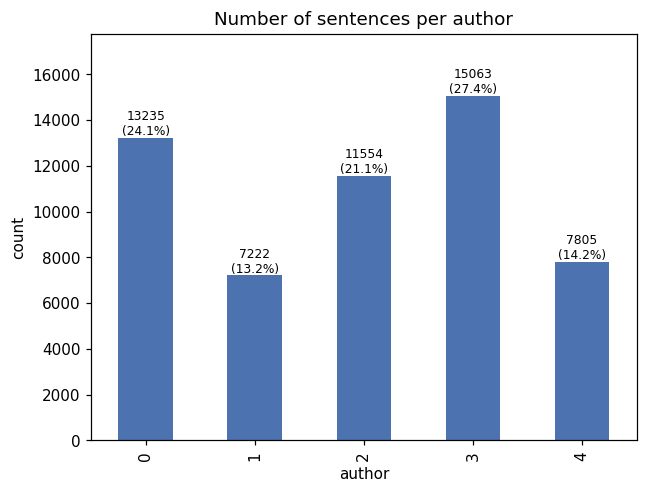

In [ ]:
cnt = train.author.value_counts().sort_index()
ax = cnt.plot.bar(color='#4C72B0')
ax.set_title('Number of sentences per author'); ax.set_xlabel('author'); ax.set_ylabel('count')
for i, v in enumerate(cnt): ax.text(i, v, f'{v}\n({v/len(train):.1%})', ha='center', va='bottom', fontsize=8)
plt.ylim(0, cnt.max()*1.18); plt.show()

- 작가 3(약 27%)과 작가 1(약 13%)이 **약 2배 차이** → 약한 불균형
- 검증 데이터를 나눌 때 `StratifiedKFold`로 작가 비율을 유지하는 게 좋습니다

### LogLoss 기준선
모델 없이 내도 나오는 점수를 먼저 알아두면, 베이스라인이 얼마나 나아졌는지 비교할 수 있습니다.

In [ ]:
from sklearn.metrics import log_loss
y = train.author.values
prior = cnt.values / cnt.sum()
print('모든 작가 1/5씩      :', round(log_loss(y, np.full((len(y), 5), 0.2)), 4))
print('작가 비율대로 제출   :', round(log_loss(y, np.tile(prior, (len(y), 1))), 4))

모든 작가 1/5씩      : 1.6094
작가 비율대로 제출   : 1.5702


- 균등 확률 ≈ **1.609**, 작가 비율 그대로 ≈ **1.57** → 베이스라인 모델은 이보다 한참 낮아야 의미가 있음

## 3. 텍스트 길이

,n_char_median,n_word_median
author,,
0,119.0,22.0
1,166.0,30.0
2,108.0,20.0
3,109.0,20.0
4,117.0,22.0


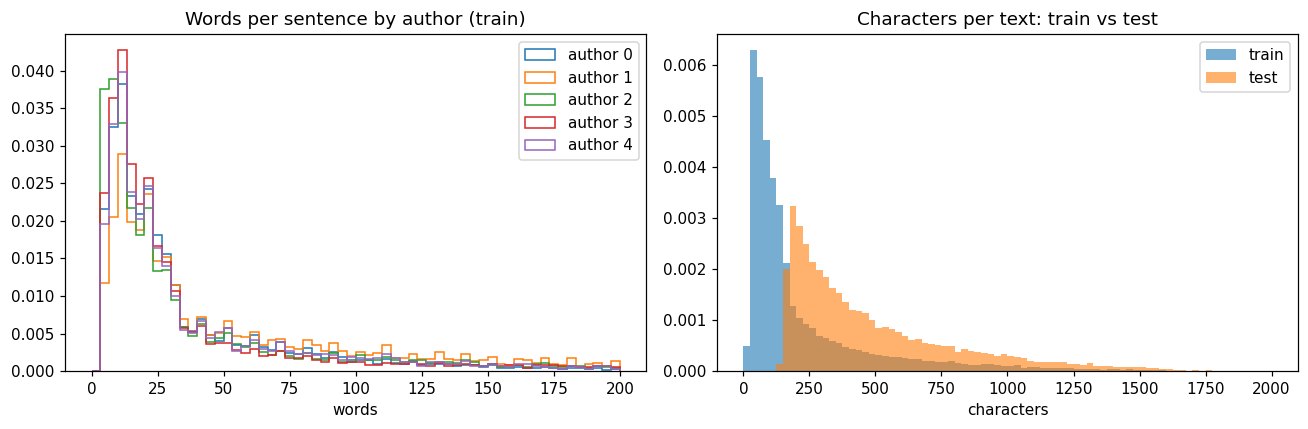

         train     test
count  54879.0  19617.0
mean     228.1    487.3
std      276.3    321.4
min        9.0    131.0
25%       63.0    242.0
50%      118.0    378.0
75%      265.0    636.0
max     2500.0   2349.0


In [ ]:
for df in (train, test):
    df['n_char'] = df.text.str.len()
    df['n_word'] = df.text.str.split().str.len()

display(train.groupby('author')[['n_char', 'n_word']].median().rename(columns=lambda c: c + '_median'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for a in sorted(train.author.unique()):
    axes[0].hist(train.loc[train.author == a, 'n_word'], bins=60, range=(0, 200), histtype='step', label=f'author {a}', density=True)
axes[0].set_title('Words per sentence by author (train)'); axes[0].legend(); axes[0].set_xlabel('words')

axes[1].hist(train.n_char, bins=80, range=(0, 2000), alpha=.6, density=True, label='train')
axes[1].hist(test.n_char, bins=80, range=(0, 2000), alpha=.6, density=True, label='test')
axes[1].set_title('Characters per text: train vs test'); axes[1].legend(); axes[1].set_xlabel('characters')
plt.tight_layout(); plt.show()

print(pd.DataFrame({'train': train.n_char.describe(), 'test': test.n_char.describe()}).round(1))

- 작가 1이 문장이 가장 긴 편(중앙값 약 30단어), 나머지는 20단어 안팎
- **test 문장이 train보다 훨씬 깁니다** (글자 수 중앙값 약 115 → 약 380, test는 최소 131자)
  - train에는 짧은 대사가 많지만 test는 긴 문단 위주 → 긴 글일수록 단서가 많아 오히려 맞히기 쉬울 수 있음
  - 길이 자체를 피처로 쓰면 train/test 분포가 달라 **오히려 해가 될 수 있으니 주의**

## 4. 문장부호 · 문체 신호
작가마다 문장부호 쓰는 습관이 다릅니다. "해당 기호가 한 번이라도 등장하는 문장 비율"을 비교해봅니다.

In [ ]:
patterns = {
    'curly quote “”': r'[“”]',
    'straight quote "': r'"',
    "apostrophe ’": r'’',
    'double hyphen --': r'--',
    'em dash —': r'—',
    'semicolon ;': r';',
    'exclamation !': r'!',
    'question ?': r'\?',
    'ellipsis ...': r'\.\.\.',
    'masked name odin': r'\bodin\b',
    'leading space': r'^\s',
    '_italic_': r'_\w',
}
punct = pd.DataFrame({
    name: list(train.groupby('author').text.apply(lambda s: s.str.contains(p, regex=True).mean()))
          + [test.text.str.contains(p, regex=True).mean()]
    for name, p in patterns.items()
}, index=[f'author {a}' for a in sorted(train.author.unique())] + ['test']).T

display(punct.style.format('{:.1%}').background_gradient(axis=1, cmap='Blues'))

,author 0,author 1,author 2,author 3,author 4,test
curly quote “”,26.8%,53.4%,72.2%,55.6%,38.6%,41.5%
"straight quote """,2.7%,15.6%,9.2%,21.5%,11.2%,10.0%
apostrophe ’,34.8%,6.5%,16.2%,30.6%,22.0%,29.3%
double hyphen --,10.2%,19.9%,3.8%,9.4%,5.9%,16.6%
em dash —,3.1%,2.5%,4.7%,3.1%,5.1%,6.6%
semicolon ;,24.6%,42.6%,6.7%,16.8%,34.6%,45.7%
exclamation !,22.7%,17.6%,13.4%,24.2%,15.9%,23.2%
question ?,24.9%,19.7%,26.6%,30.6%,21.3%,20.0%
ellipsis ...,0.0%,0.2%,0.1%,11.9%,0.1%,5.1%
masked name odin,43.9%,61.7%,31.5%,49.2%,40.8%,59.7%


**발견**
- `;` 세미콜론: 작가 2는 약 7%, 작가 1은 약 43% → **6배 차이**
- `...` 말줄임표: **거의 작가 3만** 사용 (약 12%, 나머지는 0%대)
- 따옴표 종류(“ vs ")와 `’`, `--`, 문장 앞 공백까지 작가별로 다름
- 즉 **문장부호가 강력한 단서** → 모델 입력용 전처리에서 함부로 지우면 안 됨

**`odin`이란?** 인물·지명 같은 **고유명사가 전부 `odin`으로 마스킹**되어 있습니다 (예: *the Brothers odin*).
이름으로 작가를 맞히지 못하게 한 장치라, 빈도 분석 시에는 `odin`을 불용어처럼 빼주는 게 좋습니다.

## 5. 단어 빈도

In [ ]:
def tokenize(s):
    s = s.lower().replace('’', "'")
    return re.findall(r"[a-z]+(?:'[a-z]+)?", s)

STOP = set(ENGLISH_STOP_WORDS) | {'odin', "odin's", "i'm", "it's", "don't", "that's", "i'll", 'said', 'says'}

top_all, top_content = {}, {}
for a in sorted(train.author.unique()):
    toks = [t for s in train.loc[train.author == a, 'text'] for t in tokenize(s)]
    c_all = Counter(toks)
    c_content = Counter(t for t in toks if t not in STOP and len(t) > 2)
    top_all[f'author {a}'] = [w for w, _ in c_all.most_common(15)]
    top_content[f'author {a}'] = [w for w, _ in c_content.most_common(15)]

print('▶ 불용어 포함 상위 15개 (기능어 사용 습관)')
display(pd.DataFrame(top_all))
print('▶ 불용어 제외 상위 15개 (주제·어휘)')
display(pd.DataFrame(top_content))

▶ 불용어 포함 상위 15개 (기능어 사용 습관)


,author 0,author 1,author 2,author 3,author 4
0,the,the,the,the,the
1,and,to,and,and,and
2,i,and,of,to,of
3,to,of,i,i,a
4,of,odin,a,of,i
5,a,a,to,a,to
6,in,i,in,he,he
7,odin,her,that,you,in
8,that,in,it,odin,was
9,it,was,was,in,odin


▶ 불용어 제외 상위 15개 (주제·어휘)


,author 0,author 1,author 2,author 3,author 4
0,little,mrs,man,know,man
1,know,miss,sir,did,like
2,time,did,come,come,cried
3,old,think,little,like,sir
4,miss,know,cried,man,good
5,man,good,came,prince,little
6,come,time,know,time,time
7,say,little,time,say,hand
8,like,say,did,suddenly,come
9,dear,soon,face,cried,came


- 불용어 포함 상위 단어는 `the, and, to, of`처럼 비슷해 보이지만, **순위와 비율 차이 자체가 문체**입니다
  (저자 판별 연구에서 가장 오래된 단서가 기능어 빈도예요)
- 불용어를 빼면 작가별 **고유 어휘**(호칭, 자주 쓰는 동사·명사 등)가 드러납니다
- 결론: **WordCloud/빈도 분석은 불용어 제거 버전**, **모델 입력은 불용어 유지**

### 작가별 '특징 단어' — 다른 작가 대비 얼마나 자주 쓰는가

In [ ]:
# 단순 빈도는 모든 작가가 공통으로 많이 쓰는 단어가 위로 올라오므로,
# '이 작가에서의 비율 / 나머지 작가에서의 비율'로 특징 단어를 뽑습니다.
counts = {a: Counter(t for s in train.loc[train.author == a, 'text'] for t in tokenize(s) if t not in STOP and len(t) > 2)
          for a in sorted(train.author.unique())}
total = sum(counts.values(), Counter())
distinct = {}
for a, c in counts.items():
    na, nrest = sum(c.values()), sum(total.values()) - sum(c.values())
    score = {w: ((c[w] + 1) / na) / ((total[w] - c[w] + 1) / nrest) for w in c if c[w] >= 30}
    distinct[f'author {a}'] = [w for w, _ in sorted(score.items(), key=lambda x: -x[1])[:15]]
display(pd.DataFrame(distinct))

,author 0,author 1,author 2,author 3,author 4
0,dora,elliot,nigel,ivan,florizel
1,joe,tilney,chodinger,stepan,herr
2,wickfield,highbury,lana,roubles,nae
3,em'ly,lizzy,hordle,moscow,rolles
4,pip,musgrove,bowman,lise,cap'n
5,trotwood,randalls,loring,rodya,aros
6,pross,benwick,phelps,varia,villon
7,heep,uppercross,hudson,totski,highness
8,carton,perry,squires,nina,poole
9,darnay,yates,humphrey,rouble,hatch


**발견: 마스킹이 완벽하지 않다**
- 특징 단어 상위권이 거의 **인물·지명**입니다 (작가 0: `pip, joe, dora` / 작가 1: `elliot, lizzy, highbury` / 작가 3: `ivan, moscow, roubles` 등)
  → 일부 고유명사만 `odin`으로 바뀌었고 **나머지 이름은 그대로 남아 있음** → 모델에게는 강력한 단서
- `chodinger`처럼 **단어 중간이 `odin`으로 치환된 흔적**도 보입니다 (이름 일부가 마스킹된 것으로 보임)
- 작가 1의 `chuse, shew`처럼 **옛 철자**도 작가 고유의 신호
- `roubles, moscow, prince`(작가 3), `cap'n, nae`(작가 4)처럼 **배경·방언 어휘**도 구분에 도움

### WordCloud (불용어·`odin` 제거)

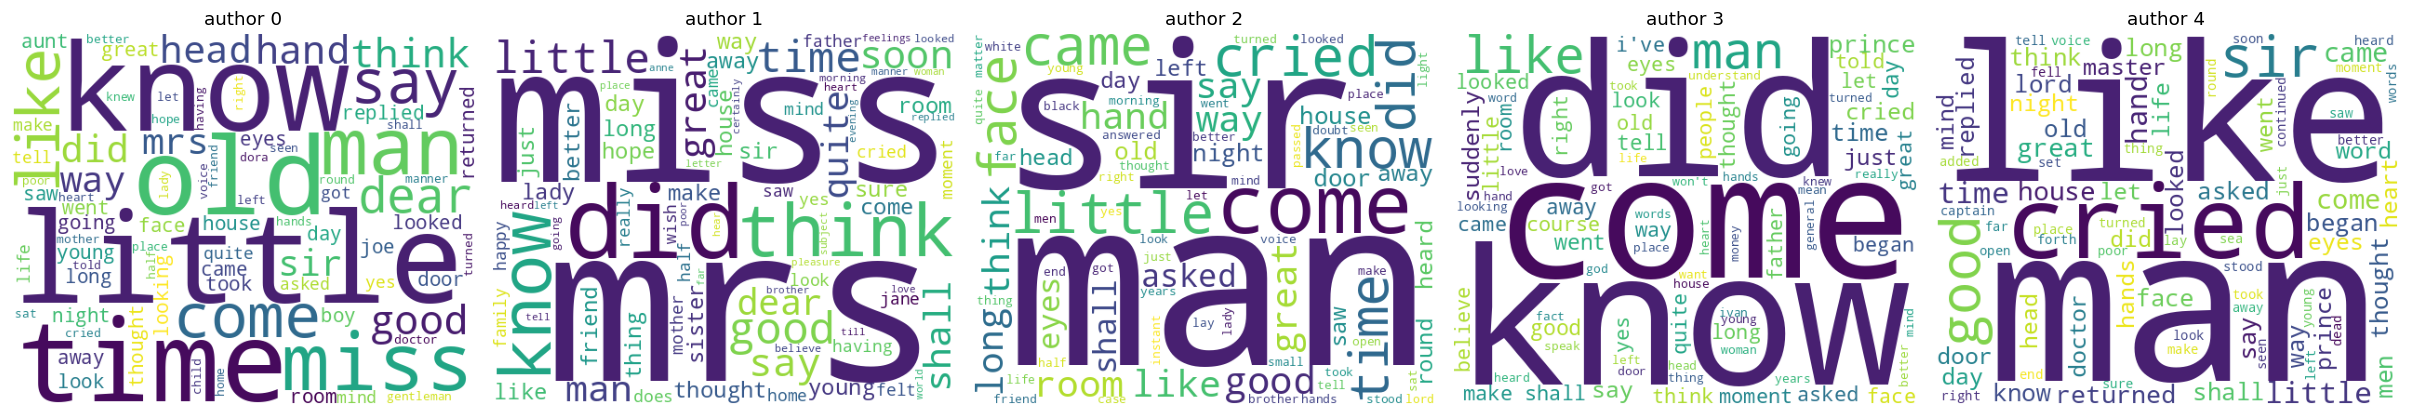

In [ ]:
try:
    from wordcloud import WordCloud
except ImportError:
    !pip -q install wordcloud
    from wordcloud import WordCloud

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (a, c) in zip(axes, counts.items()):
    wc = WordCloud(width=500, height=400, background_color='white', max_words=80, random_state=42).generate_from_frequencies(c)
    ax.imshow(wc); ax.set_title(f'author {a}'); ax.axis('off')
plt.tight_layout(); plt.show()

## 6. 전처리

| | (A) 분석·시각화용 `text_eda` | (B) 모델 입력용 `text_model` |
|---|---|---|
| 앞뒤 공백 | 제거 | 제거 |
| 연속 공백 | 하나로 | 하나로 |
| 소문자화 | O | O |
| 문장부호 | 제거 | **유지** (따옴표만 통일 여부 실험) |
| 불용어 | 제거 | **유지** |
| `odin` | 제거 | **유지** (고유명사 자리 = 문장 구조 정보) |

그리고 행 단위로:
1. `* * * * *` 같은 **구분 기호만 있는 행 제거**
2. **같은 문장·다른 작가** 충돌 행 제거
3. 나머지 완전 중복은 1개만 남김

In [ ]:
before = len(train)

# 1) 알파벳이 하나도 없는 행 (예: ' * * * * *') 제거
train = train[train.text.str.contains(r'[A-Za-z]')]
# 2) 같은 문장인데 작가가 다른 행 제거
n_auth = train.groupby('text').author.transform('nunique')
train = train[n_auth == 1]
# 3) 완전 중복 제거
train = train.drop_duplicates(subset=['text', 'author']).reset_index(drop=True)
print(f'{before} → {len(train)} 행 ({before - len(train)}개 제거)')

54879 → 54739 행 (140개 제거)


In [ ]:
def clean_basic(s):
    s = s.strip()
    s = re.sub(r'\s+', ' ', s)
    return s

def clean_for_model(s, unify_quotes=False):
    s = clean_basic(s).lower()
    if unify_quotes:   # 따옴표 모양 통일: 실험용 옵션 (아래 설명 참고)
        s = s.replace('“', '"').replace('”', '"').replace('‘', "'").replace('’', "'")
    return s

def clean_for_eda(s):
    toks = tokenize(clean_basic(s))
    return ' '.join(t for t in toks if t not in STOP and len(t) > 2)

for df in (train, test):
    df['text_model'] = df.text.apply(clean_for_model)
    df['text_eda'] = df.text.apply(clean_for_eda)

display(train[['text', 'text_model', 'text_eda']].sample(5, random_state=0))

,text,text_model,text_eda
44382,"'He is very pretty,' said odin. 'Will you kiss me, my pretty little fellow?'","'he is very pretty,' said odin. 'will you kiss me, my pretty little fellow?'",pretty kiss pretty little fellow
49416,"Miss odin did so, and odin, after a careful examination through the open window, endeavoured in every way to force the shutter open, but without success. There was no slit through which a knife co...","miss odin did so, and odin, after a careful examination through the open window, endeavoured in every way to force the shutter open, but without success. there was no slit through which a knife co...",miss did careful examination open window endeavoured way force shutter open success slit knife passed raise bar lens tested hinges solid iron built firmly massive masonry hum scratching chin perpl...
11204,This eternal reading of riddles was too much for me. I felt that I must put a term to it.,this eternal reading of riddles was too much for me. i felt that i must put a term to it.,eternal reading riddles felt term
9378,"""Olympia is mine, friends, that's agreed!"" cried odin.","""olympia is mine, friends, that's agreed!"" cried odin.",olympia friends agreed cried
4497,"""Now, Chodinger, if you really insist upon being the first man in,"" said Lord odin, when every preparation was complete.","""now, chodinger, if you really insist upon being the first man in,"" said lord odin, when every preparation was complete.",chodinger really insist man lord preparation complete


**따옴표 통일(`unify_quotes`)은 왜 옵션인가?**
4번 표에서 보듯 “ 와 " 의 사용 비율이 작가마다 다릅니다. 이건 작가의 습관이라기보다 **원본 책 파일(판본)의 차이**일 가능성이 크지만,
train/test가 같은 출처라면 그대로 둘 때 성능이 오를 수 있습니다.
→ 베이스라인에서 **둘 다 돌려보고 검증 점수로 결정**하면 보고서에 쓸 실험 거리도 됩니다.

In [ ]:
train[['index', 'text', 'text_model', 'text_eda', 'author']].to_csv('train_clean.csv', index=False)
test[['index', 'text', 'text_model', 'text_eda']].to_csv('test_clean.csv', index=False)
print('saved: train_clean.csv', train.shape, '/ test_clean.csv', test.shape)

saved: train_clean.csv (54739, 7) / test_clean.csv (19617, 6)


## 7. EDA 요약
1. train 54,879문장 / test 19,617문장, 결측치 없음. 작가 5명(0~4), 작가 3이 27%, 작가 1이 13%로 약한 불균형 → Stratified 분할
2. 제출은 작가별 **확률** 5개, 평가 지표는 **LogLoss** → 확률을 잘 내는 모델(Logistic Regression 등)이 유리. 기준선: 균등 확률 1.609 / 작가 비율 1.57
3. 고유명사는 `odin`으로 마스킹되어 있지만 **일부 이름·지명은 그대로 남아 있어** 강력한 단서가 됨 (작가별 특징 단어 상위권이 대부분 인물명)
4. 작가별 문장부호 습관 차이가 큼 (`;` 6배 차이, `...`는 거의 작가 3 전용) → 모델 입력에서 문장부호·불용어 **유지**
5. **test 문장이 train보다 약 3배 길다** → 길이 피처 사용 주의, 검증 점수가 실제 점수보다 낮게 나올 수 있음
6. 구분 기호 행, 작가 충돌 중복 제거

## 8. 다음 단계 (베이스라인 설계)
- 벡터화: 단어 TF-IDF(1-2gram) + **문자 TF-IDF(char 2-5gram)** — 문자 n-gram은 문장부호·어미 습관을 자연스럽게 잡아줌
- 모델: Logistic Regression으로 시작 → `StratifiedKFold(5)`로 검증, 지표는 대회 지표(LogLoss) 기준
- 비교 실험: 따옴표 통일 O/X, 불용어 제거 O/X

Sol 1) 딥러닝_RoBERTa 모델

In [ ]:
!pip install -q transformers datasets accelerate

In [ ]:
import torch
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset
import gc

# 메모리 정리 (OOM 방지)
gc.collect()
torch.cuda.empty_cache()

# 1. 데이터 세팅
# RoBERTa는 대소문자, 문장부호에서 문체를 파악하므로 전처리 이전의 'text' 원본을 사용
train_text = train['text'].values
train_labels = train['author'].values
test_text = test['text'].values

# Stratified Split
X_train, X_val, y_train, y_val = train_test_split(
    train_text, train_labels,
    test_size=0.2,
    random_state=42,
    stratify=train_labels
)

# 2. 토크나이저 로드 (roberta-base 모델)
MODEL_NAME = "roberta-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# 3. 데이터셋 변환 (Hugging Face Dataset 포맷)
def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=256)

train_dataset = Dataset.from_dict({'text': X_train, 'label': y_train})
val_dataset = Dataset.from_dict({'text': X_val, 'label': y_val})
test_dataset = Dataset.from_dict({'text': test_text})

print("텍스트 토큰화 진행 중")
train_dataset = train_dataset.map(tokenize_function, batched=True)
val_dataset = val_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

# 4. 평가 지표 함수 (LogLoss 계산)
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    # Logits를 Softmax 확률값으로 변환
    probs = F.softmax(torch.tensor(predictions), dim=-1).numpy()
    loss = log_loss(labels, probs)
    return {"log_loss": loss}

# 5. 모델 로드
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=5)

# 6. 학습 설정 (TrainingArguments)
training_args = TrainingArguments(
    output_dir='./results',
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="log_loss",
    greater_is_better=False,
    fp16=True,
    report_to="none"
)

# 7. 트레이너 객체 생성 및 학습
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

print("\nRoBERTa 모델 학습 시작")
trainer.train()

# 8. 검증 데이터 최종 LogLoss 확인
eval_results = trainer.evaluate()
print(f"\n▶ Validation LogLoss: {eval_results['eval_log_loss']:.4f}")

텍스트 토큰화 진행 중


Map:   0%|          | 0/43791 [00:00<?, ? examples/s]

Map:   0%|          | 0/10948 [00:00<?, ? examples/s]

Map:   0%|          | 0/19617 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Log Loss,Runtime,Samples Per Second,Steps Per Second
0.244611,0.398124,3,0.398123,39.171900,279.486000,8.756000



▶ Validation LogLoss: 0.3981


Sol 2) 시현이 베이스라인

- 벡터화: 단어 TF-IDF(1-2gram) + 문자 TF-IDF(char 2-5gram) — 문자 n-gram은 문장부호·어미 습관을 자연스럽게 잡아줌

- 모델: Logistic Regression으로 시작 → StratifiedKFold(5)로 검증, 지표는 대회 지표(LogLoss) 기준

- 비교 실험: 따옴표 통일 O/X, 불용어 제거 O/X

In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss
from scipy.sparse import hstack
import time

# train = pd.read_csv('train_clean.csv')
# test = pd.read_csv('test_clean.csv')

# '따옴표 통일' 컬럼 추가
# 기존 clean_for_model 함수를 활용하거나, 정규식으로 간단히 치환
train['text_model_unified'] = train['text_model'].str.replace(r'[“”]', '"', regex=True).str.replace(r'[‘’]', "'", regex=True)
test['text_model_unified'] = test['text_model'].str.replace(r'[“”]', '"', regex=True).str.replace(r'[‘’]', "'", regex=True)

print("데이터 준비 완료")

데이터 준비 완료


In [ ]:
def run_experiment(train_df, text_col, desc):
    print(f"{desc} (사용 컬럼: {text_col})")

    X_text = train_df[text_col].fillna('')
    y = train_df['author'].values

    # 1. 벡터화 (Word & Char TF-IDF)
    # 메모리 초과(OOM) 방지와 노이즈 제거를 위해 min_df 설정
    word_vec = TfidfVectorizer(analyzer='word', ngram_range=(1, 2), min_df=2)
    char_vec = TfidfVectorizer(analyzer='char', ngram_range=(2, 5), min_df=3)

    start_time = time.time()
    X_word = word_vec.fit_transform(X_text)
    X_char = char_vec.fit_transform(X_text)

    # 두 희소 행렬(Sparse Matrix) 가로로 합치기
    X = hstack([X_word, X_char])
    print(f"Feature 추출 완료 (차원: {X.shape})")

    # 2. 교차 검증 (StratifiedKFold)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    oof_preds = np.zeros((len(train_df), 5))
    fold_losses = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
        # CSR 포맷으로 변환하여 인덱싱 속도 향상
        X_tr, y_tr = X.tocsr()[train_idx], y[train_idx]
        X_va, y_va = X.tocsr()[val_idx], y[val_idx]

        # Logistic Regression
        # C=3.0 정도로 규제를 살짝 풀어주면 텍스트 분류에서 성능이 오르는 경향이 있음
        model = LogisticRegression(C=3.0, max_iter=1000, random_state=42, n_jobs=-1)
        model.fit(X_tr, y_tr)

        # 확률 예측
        val_preds = model.predict_proba(X_va)
        oof_preds[val_idx] = val_preds

        fold_loss = log_loss(y_va, val_preds)
        fold_losses.append(fold_loss)
        print(f" Fold {fold} LogLoss: {fold_loss:.4f}")

    cv_loss = log_loss(y, oof_preds)
    print(f"-> 최종 OOF LogLoss: {cv_loss:.4f}\n")

    return cv_loss, word_vec, char_vec

# 3가지 가설 비교 실험 실행
results = {}

# [실험 A] 불용어/문장부호 유지, 따옴표 원본 (베이스라인)
results['1. Base (기본 모델용)'] = run_experiment(train, 'text_model', '불용어/문장부호 유지, 원본 따옴표')

# [실험 B] 불용어/문장부호 유지, 따옴표 통일
results['2. Unified Quotes'] = run_experiment(train, 'text_model_unified', '불용어/문장부호 유지, 따옴표 통일')

# [실험 C] 불용어 및 문장부호 제거 (EDA용 데이터)
results['3. Cleaned (EDA용)'] = run_experiment(train, 'text_eda', '불용어 및 문장부호 제거')

# 결과 요약
print("-"*40)
print("결과 요약 (LogLoss - 낮을수록 좋음)")
for desc, (loss, _, _) in results.items():
    print(f"{desc:<25} : {loss:.4f}")

불용어/문장부호 유지, 원본 따옴표 (사용 컬럼: text_model)
Feature 추출 완료 (차원: (54739, 406603))
 Fold 1 LogLoss: 0.4974
 Fold 2 LogLoss: 0.4955
 Fold 3 LogLoss: 0.5014
 Fold 4 LogLoss: 0.5061
 Fold 5 LogLoss: 0.5079
-> 최종 OOF LogLoss: 0.5017

불용어/문장부호 유지, 따옴표 통일 (사용 컬럼: text_model_unified)
Feature 추출 완료 (차원: (54739, 399625))
 Fold 1 LogLoss: 0.5027
 Fold 2 LogLoss: 0.5039
 Fold 3 LogLoss: 0.5098
 Fold 4 LogLoss: 0.5131
 Fold 5 LogLoss: 0.5133
-> 최종 OOF LogLoss: 0.5085

불용어 및 문장부호 제거 (사용 컬럼: text_eda)
Feature 추출 완료 (차원: (54739, 229536))
 Fold 1 LogLoss: 0.7367
 Fold 2 LogLoss: 0.7368
 Fold 3 LogLoss: 0.7511
 Fold 4 LogLoss: 0.7672
 Fold 5 LogLoss: 0.7600
-> 최종 OOF LogLoss: 0.7504

----------------------------------------
결과 요약 (LogLoss - 낮을수록 좋음)
1. Base (기본 모델용)          : 0.5017
2. Unified Quotes         : 0.5085
3. Cleaned (EDA용)         : 0.7504


예상되는 결과 해석 및 다음 스텝 (Submission)
실험 3(Cleaned)의 점수가 가장 나쁠 확률이 높습니다. 문장부호(;, ..., 따옴표)와 기능어(the, of)가 모두 날아갔기 때문에, Word/Char TF-IDF가 작가의 고유 문체 신호를 잡아내지 못합니다.

실험 1(Base)과 실험 2(Unified) 중 더 점수가 낮은(좋은) 컬럼을 최종 데이터로 선택합니다. (일반적으로 판본 차이로 인한 노이즈라면 Unified가 좋고, 작가 본연의 습관이라면 Base가 좋습니다.)

In [ ]:
# 최종 모델(Base) 전체 데이터 재학습 및 예측
best_text_col = 'text_model'

X_train_text = train[best_text_col].fillna('')
X_test_text = test[best_text_col].fillna('')
y_train = train['author'].values

# 벡터라이저 재학습 (Train 전체 데이터 기준)
word_vec_final = TfidfVectorizer(analyzer='word', ngram_range=(1, 2), min_df=2)
char_vec_final = TfidfVectorizer(analyzer='char', ngram_range=(2, 5), min_df=3)

X_train_word = word_vec_final.fit_transform(X_train_text)
X_train_char = char_vec_final.fit_transform(X_train_text)
X_train_final = hstack([X_train_word, X_train_char]).tocsr()

X_test_word = word_vec_final.transform(X_test_text)
X_test_char = char_vec_final.transform(X_test_text)
X_test_final = hstack([X_test_word, X_test_char]).tocsr()

# 모델 학습
final_model = LogisticRegression(C=3.0, max_iter=1000, random_state=42, n_jobs=-1)
final_model.fit(X_train_final, y_train)

# Test 데이터 확률 예측
test_preds = final_model.predict_proba(X_test_final)

# 제출 파일 생성
sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
sub[['0', '1', '2', '3', '4']] = test_preds

submission_filename = 'submission_baseline.csv'
sub.to_csv(submission_filename, index=False)
print(f"제출 파일 저장 완료: {submission_filename} (Shape: {sub.shape})")
display(sub.head())

제출 파일 저장 완료: submission_baseline.csv (Shape: (19617, 6))


,index,0,1,2,3,4
0,0,0.080721,0.344587,0.488135,0.080878,0.005678
1,1,0.171214,0.651619,0.011574,0.121861,0.043732
2,2,0.966734,0.014068,0.006889,0.006010,0.006299
3,3,0.014118,0.000210,0.935846,0.000345,0.049480
4,4,0.874807,0.059460,0.012566,0.046089,0.007077
